Deep Learning Part 1

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [4]:
import seaborn as sns
import matplotlib.pyplot as mat
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical


Data Extraction and Cleaning (USA Accidents)

In [5]:
df=pd.read_csv(r'L:\4th sem\Mission Scopus\ML Datasets\US Accidents\US_Accidents_March23.csv')
df.head(3)

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day


In [6]:
df.shape

(7728394, 46)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7728394 entries, 0 to 7728393
Data columns (total 46 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   ID                     str    
 1   Source                 str    
 2   Severity               int64  
 3   Start_Time             str    
 4   End_Time               str    
 5   Start_Lat              float64
 6   Start_Lng              float64
 7   End_Lat                float64
 8   End_Lng                float64
 9   Distance(mi)           float64
 10  Description            str    
 11  Street                 str    
 12  City                   str    
 13  County                 str    
 14  State                  str    
 15  Zipcode                str    
 16  Country                str    
 17  Timezone               str    
 18  Airport_Code           str    
 19  Weather_Timestamp      str    
 20  Temperature(F)         float64
 21  Wind_Chill(F)          float64
 22  Humidity(%)            float6

In [8]:
df.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight'],
      dtype='str')

In [9]:
df.isnull().sum()

ID                             0
Source                         0
Severity                       0
Start_Time                     0
End_Time                       0
Start_Lat                      0
Start_Lng                      0
End_Lat                  3402762
End_Lng                  3402762
Distance(mi)                   0
Description                    5
Street                     10869
City                         253
County                         0
State                          0
Zipcode                     1915
Country                        0
Timezone                    7808
Airport_Code               22635
Weather_Timestamp         120228
Temperature(F)            163853
Wind_Chill(F)            1999019
Humidity(%)               174144
Pressure(in)              140679
Visibility(mi)            177098
Wind_Direction            175206
Wind_Speed(mph)           571233
Precipitation(in)        2203586
Weather_Condition         173459
Amenity                        0
Bump      

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.shape

(7728394, 46)

In [12]:
df_selected= df[['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)', 'Severity']]
df_selected.head(3)

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Severity
0,36.9,NaN,91.0,29.68,10.0,NaN,0.02,3
1,37.9,NaN,100.0,29.65,10.0,NaN,0.00,2
2,36.0,33.3,100.0,29.67,10.0,3.5,NaN,2


In [13]:
df_selected.fillna(df_selected.mean(), inplace=True)
df_selected.head(3)

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Severity
0,36.9,58.251048,91.0,29.68,10.0,7.68549,0.020000,3
1,37.9,58.251048,100.0,29.65,10.0,7.68549,0.000000,2
2,36.0,33.300000,100.0,29.67,10.0,3.50000,0.008407,2


In [14]:
df_selected.isnull().sum()

Temperature(F)       0
Wind_Chill(F)        0
Humidity(%)          0
Pressure(in)         0
Visibility(mi)       0
Wind_Speed(mph)      0
Precipitation(in)    0
Severity             0
dtype: int64

In [15]:
df_selected['Severity'].value_counts()

Severity
2    6156981
3    1299337
4     204710
1      67366
Name: count, dtype: int64

Here, 1 and 2 are low severity and 3 and 4 are high severity. So, this time I want to classify the crash severity into 2 categories only i.e 0 for low and 1 for high. I will keep the original column of severity also.
For 0 and 1 classification, I will use Sigmoid Activation Function.

In [16]:
df_selected['Severity_Classified'] = df_selected['Severity'].apply(lambda x: 0 if x <= 2 else 1)
df_selected.head(3)

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Severity,Severity_Classified
0,36.9,58.251048,91.0,29.68,10.0,7.68549,0.020000,3,1
1,37.9,58.251048,100.0,29.65,10.0,7.68549,0.000000,2,0
2,36.0,33.300000,100.0,29.67,10.0,3.50000,0.008407,2,0


In [17]:
df_selected["Severity_Classified"].value_counts()

Severity_Classified
0    6224347
1    1504047
Name: count, dtype: int64

To prevent data leakage, I will remove column "Severity" because it directly gives the value of "Severity_Classified" and can't be used as input variable.

In [18]:
df_selected.drop(['Severity'], axis=1, inplace=True)
df_selected.head(3)

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Severity_Classified
0,36.9,58.251048,91.0,29.68,10.0,7.68549,0.020000,1
1,37.9,58.251048,100.0,29.65,10.0,7.68549,0.000000,0
2,36.0,33.300000,100.0,29.67,10.0,3.50000,0.008407,0


In Machine Learning I used to use Standarization, but in Deep Learning I will use Normalization (Min-Max Scaler)

In [19]:
X= df_selected[['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']]
y= df_selected['Severity_Classified']

In [20]:
X_min = X.min()
X_max = X.max()
X_scaled = (X - X_min) / (X_max - X_min + 1e-8)  # Adding a small constant to avoid division by zero

In [21]:
X_scaled.head(3)

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
0,0.425338,0.497470,0.909091,0.506225,0.071429,0.00707,0.000548
1,0.428716,0.497470,1.000000,0.505714,0.071429,0.00707,0.000000
2,0.422297,0.413176,1.000000,0.506055,0.071429,0.00322,0.000231


Split, Train, Test

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

Now, train the model from keras (Tensorflow) for ANN.

In [23]:
model = keras.Sequential([layers.Input(shape=(X_train.shape[1],)), layers.Dense(8, activation='relu'), layers.Dense(1, activation='sigmoid')])

Here, layers.Input= Input layer, middle one layers.Dense= Hidden layer and final layer.Dense= Output layer. I can create more hidden layers also.

Compile the model with optimizer before training

In [24]:
model.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])

sgd= Simple Gradient Descent

In [41]:
model_train = model.fit(X_train.values, y_train.values, validation_data=(X_test.values, y_test.values), epochs=10, batch_size=32, verbose=1)

Epoch 1/10
193210/193210 ━━━━━━━━━━━━━━━━━━━━ 955s 5ms/step - accuracy: 0.8055 - loss: 0.4902 - val_accuracy: 0.8048 - val_loss: 0.4887
Epoch 2/10
193210/193210 ━━━━━━━━━━━━━━━━━━━━ 691s 3ms/step - accuracy: 0.8055 - loss: 0.4854 - val_accuracy: 0.8048 - val_loss: 0.4861
Epoch 3/10
193210/193210 ━━━━━━━━━━━━━━━━━━━━ 578s 3ms/step - accuracy: 0.8054 - loss: 0.4838 - val_accuracy: 0.8048 - val_loss: 0.4851
Epoch 4/10
193210/193210 ━━━━━━━━━━━━━━━━━━━━ 649s 3ms/step - accuracy: 0.8054 - loss: 0.4830 - val_accuracy: 0.8048 - val_loss: 0.4845
Epoch 5/10
193210/193210 ━━━━━━━━━━━━━━━━━━━━ 701s 4ms/step - accuracy: 0.8053 - loss: 0.4824 - val_accuracy: 0.8047 - val_loss: 0.4840
Epoch 6/10
193210/193210 ━━━━━━━━━━━━━━━━━━━━ 717s 4ms/step - accuracy: 0.8053 - loss: 0.4819 - val_accuracy: 0.8047 - val_loss: 0.4836
Epoch 7/10
193210/193210 ━━━━━━━━━━━━━━━━━━━━ 659s 3ms/step - accuracy: 0.8052 - loss: 0.4814 - val_accuracy: 0.8046 - val_loss: 0.4833
Epoch 8/10
193210/193210 ━━━━━━━━━━━━━━━━━━━━ 64

It becomes fast, when I increase batch size.
For the binary classification (0 and 1) like "Severity_Classified", I should use "Binary Cross Entropy" as loss function and "Sigmoid" as activation function whereas for categorical classification (0,1,2,3,4,5...) like "Severity", (I should use "Categorical Cross Entropy" as loss function and "Softmax" as activation function when I do One-Hot Encoding (This encoding has multiple output variable, so I should use multiple outputs in a layer), whereas for label encoding, I should use "Sparse Categorical Cross Entropy" as loss function and "Softmax" as activation function (also use multiple outputs in a layer)).

In [42]:
df_selected.to_csv(r"L:\4th sem\Mission Scopus\ML Datasets\US Accidents\df_selected.csv", index=False)

Optimizers

I can use optimizers as my desired learning rate and momentum value in order to reduce noise.

In [25]:
from tensorflow.keras import optimizers

In [26]:
optm = optimizers.SGD(learning_rate=0.01, momentum=0.9)

Now, this time I will remove column "Severity_Classified" and do for label encoding i.e. for column "Severity"
I will do Perceptron training first and
I will do ANN training by using optimizer=optm, activation=softmax, loss=sparse categorical cross entropy 

In [27]:
df_selected.head(3)

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Severity_Classified
0,36.9,58.251048,91.0,29.68,10.0,7.68549,0.020000,1
1,37.9,58.251048,100.0,29.65,10.0,7.68549,0.000000,0
2,36.0,33.300000,100.0,29.67,10.0,3.50000,0.008407,0


In [28]:
df_selected2 = df_selected.drop(columns=["Severity_Classified"])
df_selected2["Severity"] = df["Severity"]

In [29]:
df_selected2.head(3)

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Severity
0,36.9,58.251048,91.0,29.68,10.0,7.68549,0.020000,3
1,37.9,58.251048,100.0,29.65,10.0,7.68549,0.000000,2
2,36.0,33.300000,100.0,29.67,10.0,3.50000,0.008407,2


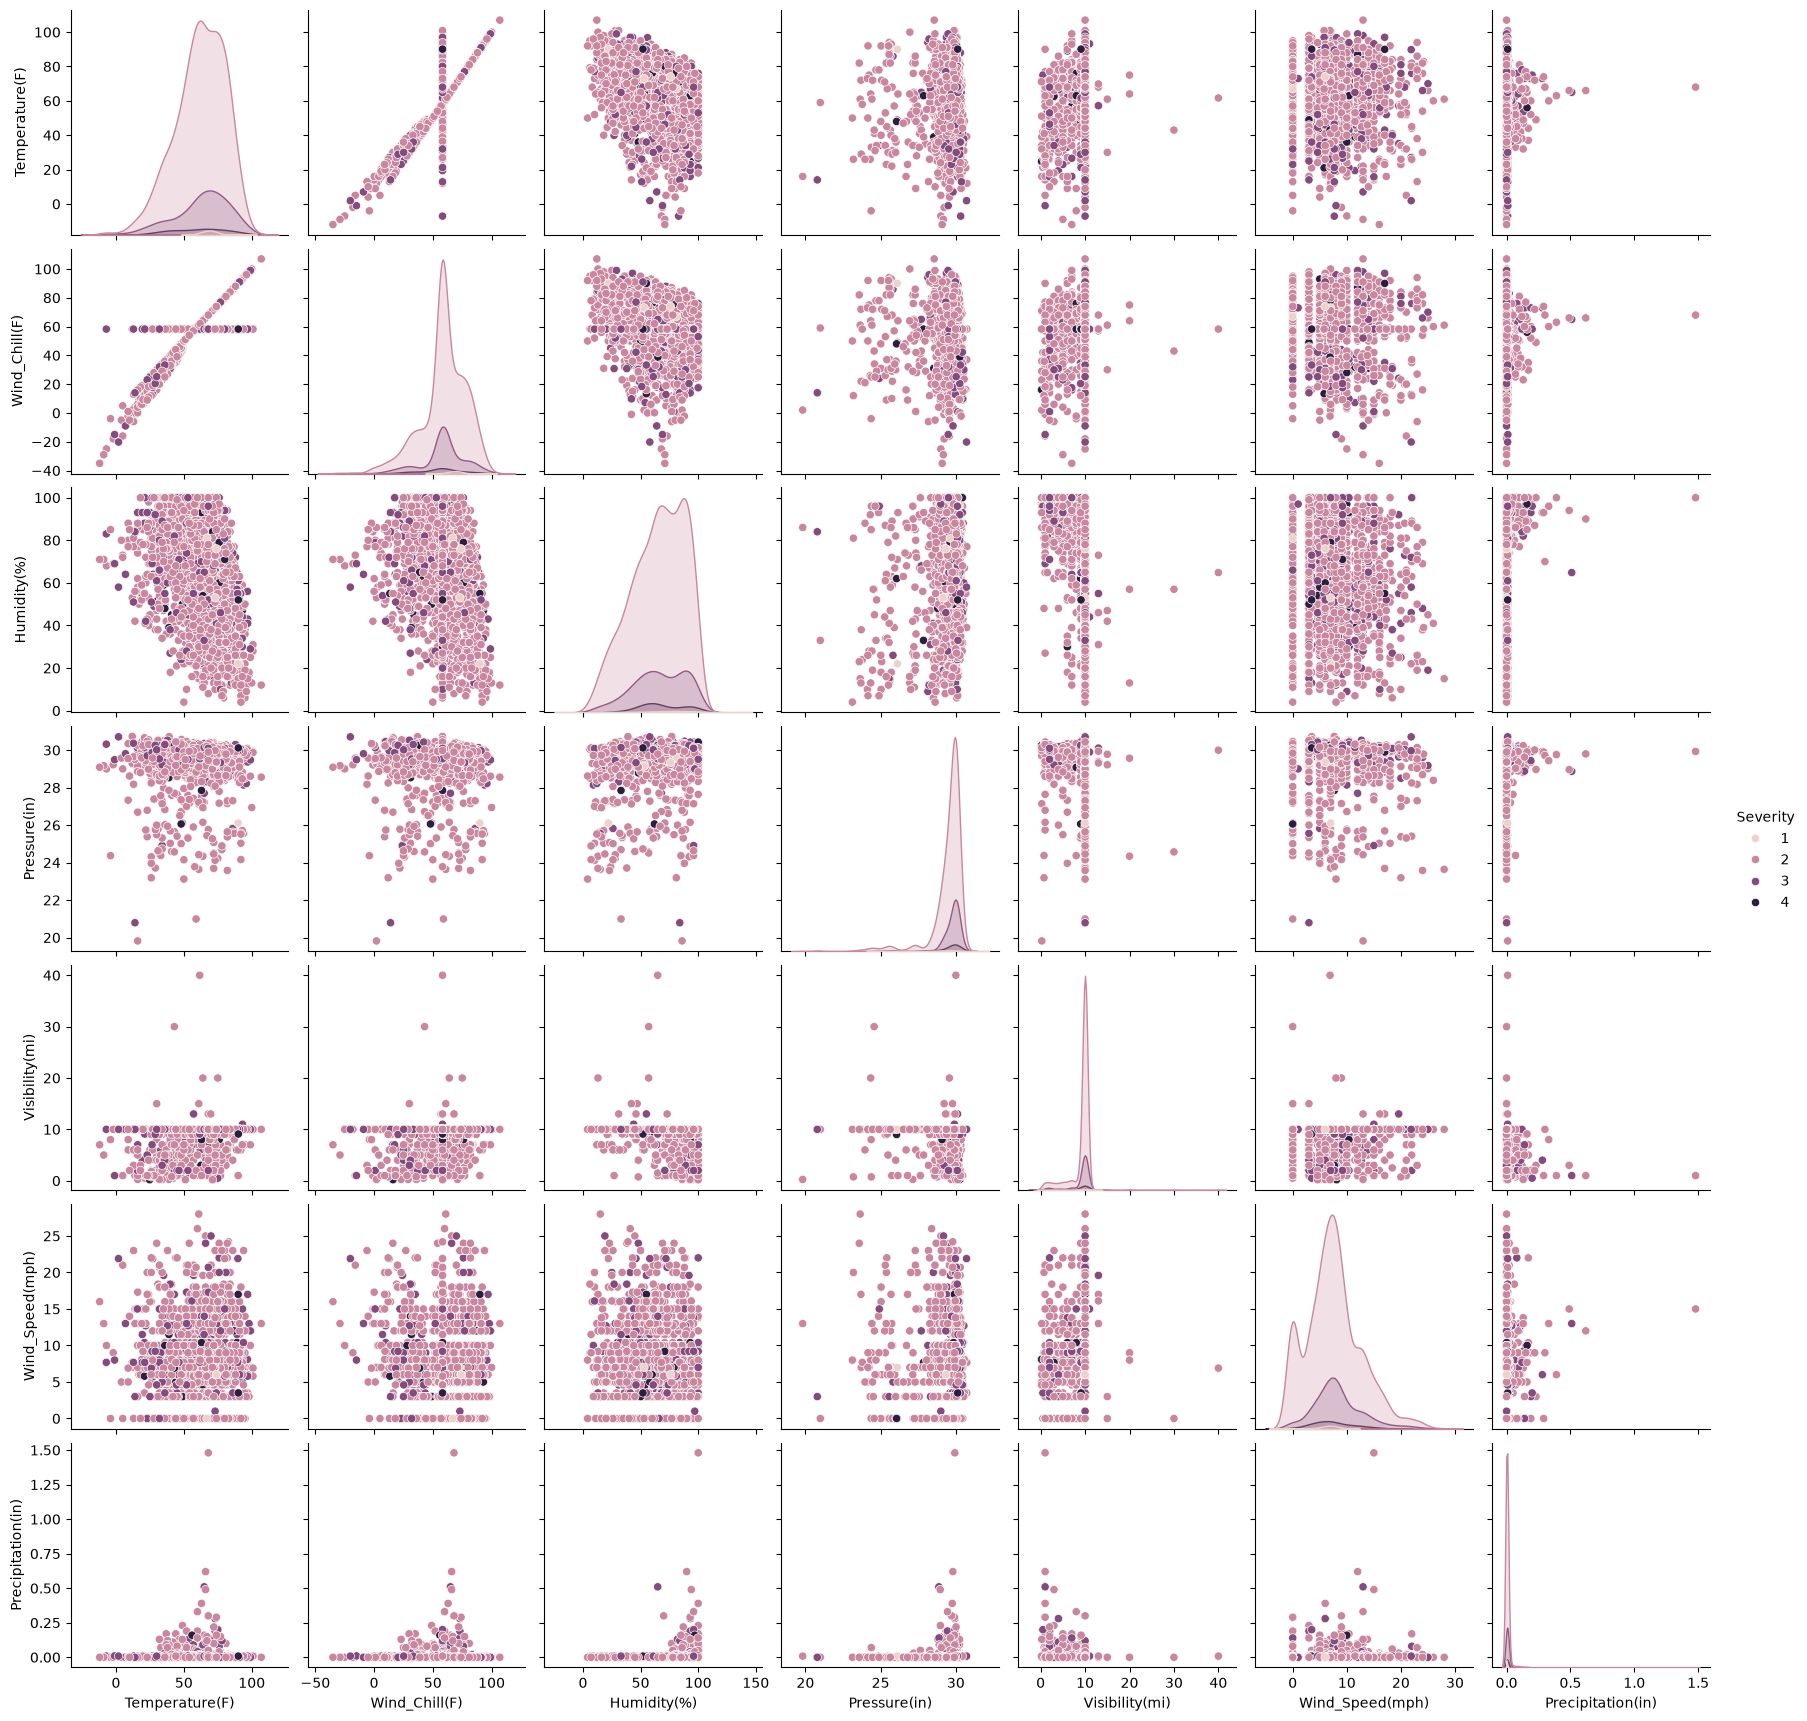

In [31]:
sample = df_selected2.sample(n=2000, random_state=1)
sns.pairplot(sample, hue="Severity")

In [32]:
X2= df_selected2[['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']]
y2= df_selected2['Severity']

I will convert values of "Severity" from 1,2,3,4 to 0,1,2,3 from Label Encoder

In [33]:
encoder = LabelEncoder()
y2 = encoder.fit_transform(df_selected2['Severity'])

In [34]:
y2

array([2, 1, 1, ..., 1, 1, 1], shape=(7728394,))

In [35]:
scaler = StandardScaler()
X2_scaled = scaler.fit_transform(X2)

In [36]:
X2_scaled = pd.DataFrame(X2_scaled, columns=X2.columns, index=X2.index)
X2_scaled.head(3)

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
0,-1.316425,3.685789e-16,1.159849,0.14144,0.342307,1.701281e-16,0.124393
1,-1.263264,3.685789e-16,1.558743,0.11135,0.342307,1.701281e-16,-0.090211
2,-1.364269,-1.294282e+00,1.558743,0.13141,0.342307,-8.017189e-01,0.000000


In [37]:
X2_train, X2_test, y2_train, y2_test = train_test_split(X2_scaled, y2, test_size=0.2, random_state=42, stratify=y2)

Perceptron Training 

In [38]:
perceptron_model = Perceptron(max_iter=1000, random_state=42)

In [72]:
perceptron_model.fit(X2_train, y2_train)

,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


Perceptron (Prediction)

In [73]:
y_pred = perceptron_model.predict(X2_test)

In [74]:
accuracy_score(y2_test, y_pred)

0.742421938837236

In [75]:
print(classification_report(y2_test, y_pred))

              precision    recall  f1-score   support

           0       0.01      0.04      0.01     13473
           1       0.80      0.93      0.86   1231396
           2       0.27      0.01      0.01    259868
           3       0.03      0.01      0.02     40942

    accuracy                           0.74   1545679
   macro avg       0.28      0.25      0.23   1545679
weighted avg       0.68      0.74      0.69   1545679



Artificial Neuron Network (ANN) Training

Since, there are 4 categories in output variable "Severity", I must use 4 outputs in an output layer.

In [39]:
model2 = keras.Sequential([layers.Input(shape=(X2_train.shape[1],)), layers.Dense(8, activation='relu'), layers.Dense(4, activation='softmax')])

In [40]:
optm2 = optimizers.SGD(learning_rate=0.02, momentum=0.9)

After I created optimizer as optm2, it should not be used as string i.e no "" is used.

In [41]:
model2.compile(optimizer=optm2, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [80]:
model2_train = model2.fit(X2_train, y2_train, validation_data=(X2_test, y2_test), epochs=10, batch_size=1000, verbose=1)

Epoch 1/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 29s 5ms/step - accuracy: 0.7957 - loss: 0.5975 - val_accuracy: 0.7963 - val_loss: 0.5896
Epoch 2/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 41s 5ms/step - accuracy: 0.7964 - loss: 0.5875 - val_accuracy: 0.7965 - val_loss: 0.5849
Epoch 3/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - accuracy: 0.7966 - loss: 0.5850 - val_accuracy: 0.7966 - val_loss: 0.5837
Epoch 4/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - accuracy: 0.7966 - loss: 0.5844 - val_accuracy: 0.7966 - val_loss: 0.5834
Epoch 5/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - accuracy: 0.7965 - loss: 0.5841 - val_accuracy: 0.7966 - val_loss: 0.5832
Epoch 6/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 34s 5ms/step - accuracy: 0.7965 - loss: 0.5839 - val_accuracy: 0.7966 - val_loss: 0.5831
Epoch 7/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - accuracy: 0.7965 - loss: 0.5837 - val_accuracy: 0.7966 - val_loss: 0.5830
Epoch 8/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 115s 17ms/step - accuracy: 0.7965 - loss:

ANN (From One Hot Encoding)

Now, I will again try from One-Hot Encoding
This time from optimizer=ADAM, activation=softmax, loss=categorical cross entropy

In [42]:
encoder2 = OneHotEncoder()
y3= encoder2.fit_transform(df_selected2[['Severity']])

In [43]:
y3

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 7728394 stored elements and shape (7728394, 4)>

In [44]:
pd.set_option('display.max_columns', None)
df_y3 = pd.DataFrame(y3.toarray(), columns=encoder2.get_feature_names_out(['Severity']))
df_y3.head(3)

,Severity_1,Severity_2,Severity_3,Severity_4
0,0.0,0.0,1.0,0.0
1,0.0,1.0,0.0,0.0
2,0.0,1.0,0.0,0.0


In [45]:
# my input features (X) - unchanged
X2_df = df_selected2[['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']]

# combine features with the one-hot encoded target, side by side, just to view together
df_selected3 = pd.concat([X2_df.reset_index(drop=True),df_y3.reset_index(drop=True)], axis=1)
df_selected3.head(3)

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Severity_1,Severity_2,Severity_3,Severity_4
0,36.9,58.251048,91.0,29.68,10.0,7.68549,0.020000,0.0,0.0,1.0,0.0
1,37.9,58.251048,100.0,29.65,10.0,7.68549,0.000000,0.0,1.0,0.0,0.0
2,36.0,33.300000,100.0,29.67,10.0,3.50000,0.008407,0.0,1.0,0.0,0.0


Convert sparse matrix of y3 to numpy, because it got memory error while training for me.

In [55]:
if hasattr(y3, "toarray"):
    y3 = y3.toarray()

In [56]:
X3_train, X3_test, y3_train, y3_test = train_test_split(X2_scaled, y3, test_size=0.2, random_state=42)

In [57]:
print(type(y3_train))

<class 'numpy.ndarray'>


In [58]:
model3 = keras.Sequential([layers.Input(shape=(X3_train.shape[1],)), layers.Dense(16, activation='leaky_relu'), layers.Dense(8, activation='relu'), layers.Dense(4, activation='softmax')])

In [59]:
model3.compile(optimizer="adam", loss='categorical_crossentropy', metrics=['accuracy'])

In [60]:
model3_train = model3.fit(X3_train, y3_train, validation_data=(X3_test, y3_test), epochs=10, batch_size=1000, validation_split=0.2, verbose=1)

Epoch 1/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 34s 5ms/step - accuracy: 0.7958 - loss: 0.5986 - val_accuracy: 0.7959 - val_loss: 0.5866
Epoch 2/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - accuracy: 0.7967 - loss: 0.5841 - val_accuracy: 0.7960 - val_loss: 0.5847
Epoch 3/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 38s 6ms/step - accuracy: 0.7968 - loss: 0.5829 - val_accuracy: 0.7960 - val_loss: 0.5838
Epoch 4/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 69s 11ms/step - accuracy: 0.7968 - loss: 0.5822 - val_accuracy: 0.7960 - val_loss: 0.5834
Epoch 5/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 37s 6ms/step - accuracy: 0.7968 - loss: 0.5818 - val_accuracy: 0.7960 - val_loss: 0.5832
Epoch 6/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 44s 6ms/step - accuracy: 0.7968 - loss: 0.5815 - val_accuracy: 0.7961 - val_loss: 0.5827
Epoch 7/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 37s 6ms/step - accuracy: 0.7968 - loss: 0.5813 - val_accuracy: 0.7961 - val_loss: 0.5825
Epoch 8/10
6183/6183 ━━━━━━━━━━━━━━━━━━━━ 35s 6ms/step - accuracy: 0.7968 - loss: 

In [61]:
loss, accuracy = model3.evaluate(X3_test, y3_test, verbose=1)

48303/48303 ━━━━━━━━━━━━━━━━━━━━ 299s 6ms/step - accuracy: 0.7961 - loss: 0.5822


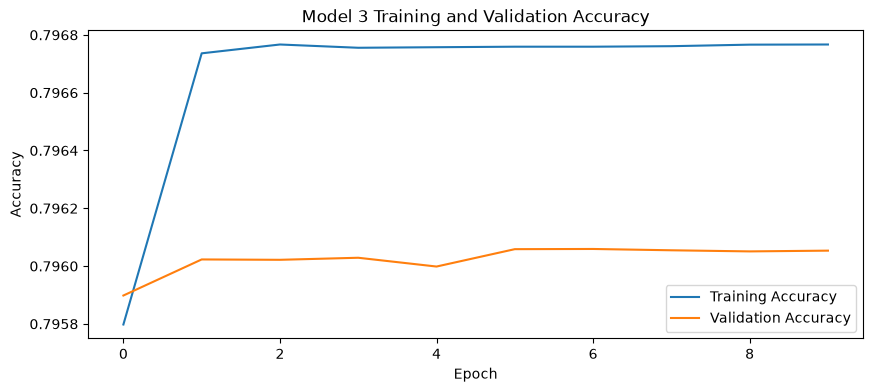

In [62]:
mat.figure(figsize=(10, 4))
mat.plot(model3_train.history['accuracy'], label='Training Accuracy')
mat.plot(model3_train.history['val_accuracy'], label='Validation Accuracy')
mat.xlabel('Epoch')
mat.ylabel('Accuracy')
mat.title('Model 3 Training and Validation Accuracy')
mat.legend()
mat.show()

In [1]:
'model' in globals()

False